# Etapa B — Hopf y ciclos límite
**Proyecto MA4703 · Red de FitzHugh–Nagumo (modelo individual)**

Este notebook usa los módulos `src/` del repositorio. Su objetivo es comprobar el análisis de Hopf del **capítulo 2 del cuaderno teórico**, detectar oscilaciones después de descartar transitorios, refinar ciclos mediante *shooting* y estudiar amplitudes y períodos.

In [1]:
using LinearAlgebra, CairoMakie, JLD2
# El kernel puede iniciar en la raíz o en notebooks/ según VS Code.
root = pwd()
if !isfile(joinpath(root, "src", "FitzHughNagumoControl.jl"))
    root = normpath(joinpath(root, ".."))
end
isfile(joinpath(root, "src", "FitzHughNagumoControl.jl")) ||
    error("Abre la carpeta del repositorio en VS Code")
include(joinpath(root, "src", "FitzHughNagumoControl.jl"))
using .FitzHughNagumoControl

p = FHNParameters(a=0.7, b=0.5, tau=12.5, I=1.4)
println("Raíz: ", root)
println("Parámetros: ", p)

Raíz: k:\Repositorios\Proyecto-COPTI\
Parámetros: FHNParameters(0.7, 0.5, 12.5, 1.4)


## 1. Hopf: resultado teórico

En un equilibrio, la traza se anula cuando

$$v_H^\pm=\pm\sqrt{1-b/\tau},\qquad I_H^\pm=(v_H^\pm)^3/3-v_H^\pm+(v_H^\pm+a)/b.$$

La frecuencia lineal es $\omega_H=\sqrt{\tau-b^2}/\tau$ y el coeficiente radial cúbico del cuaderno es

$$\kappa=\frac{(2b-1)\tau-b^2}{8(\tau-b^2)}.$$

- $\kappa<0$: supercrítica (ciclos pequeños estables del lado inestable del equilibrio).
- $\kappa>0$: subcrítica (ciclos pequeños inestables del lado estable).
- $\kappa=0$: caso degenerado; no se clasifica por el término cúbico.

In [2]:
h = hopf_analysis(p)
@show h.I_minus h.I_plus h.omega h.period_linear h.kappa h.kind
@show h.slope_minus h.slope_plus

for Ival in (h.I_minus-0.1, h.I_minus+0.1, h.I_plus-0.1, h.I_plus+0.1)
    info = stability_info(with_current(p,Ival))
    println("I=", round(Ival,digits=4), ": ", info.classification,
            ", traza=", round(info.trace,digits=6))
end

h.I_minus = 0.10666941581048195
h.I_plus = 2.6933305841895177
h.omega = 0.28
h.period_linear = 22.439947525641376
h.kappa = -0.002551020408163265
h.kind = :supercritical
h.slope_minus = 0.49989586587411794
h.slope_plus = -0.49989586587411794
I=0.0067: stable, traza=-0.099989
I=0.2067: unstable, traza=0.099875
I=2.5933: unstable, traza=0.099875
I=2.7933: stable, traza=-0.099989


In [3]:
p_sub = FHNParameters(a=0.7,b=0.8,tau=4.0,I=1.4)
@show hopf_analysis(p_sub).kind hopf_analysis(p_sub).kappa

(hopf_analysis(p_sub)).kind = :subcritical
(hopf_analysis(p_sub)).kappa = 0.0654761904761905


0.0654761904761905

## 2. Ramas de equilibrio y estabilidad

Las líneas verticales marcan las corrientes críticas. La gráfica del equilibrio **no** representa los ciclos periódicos.

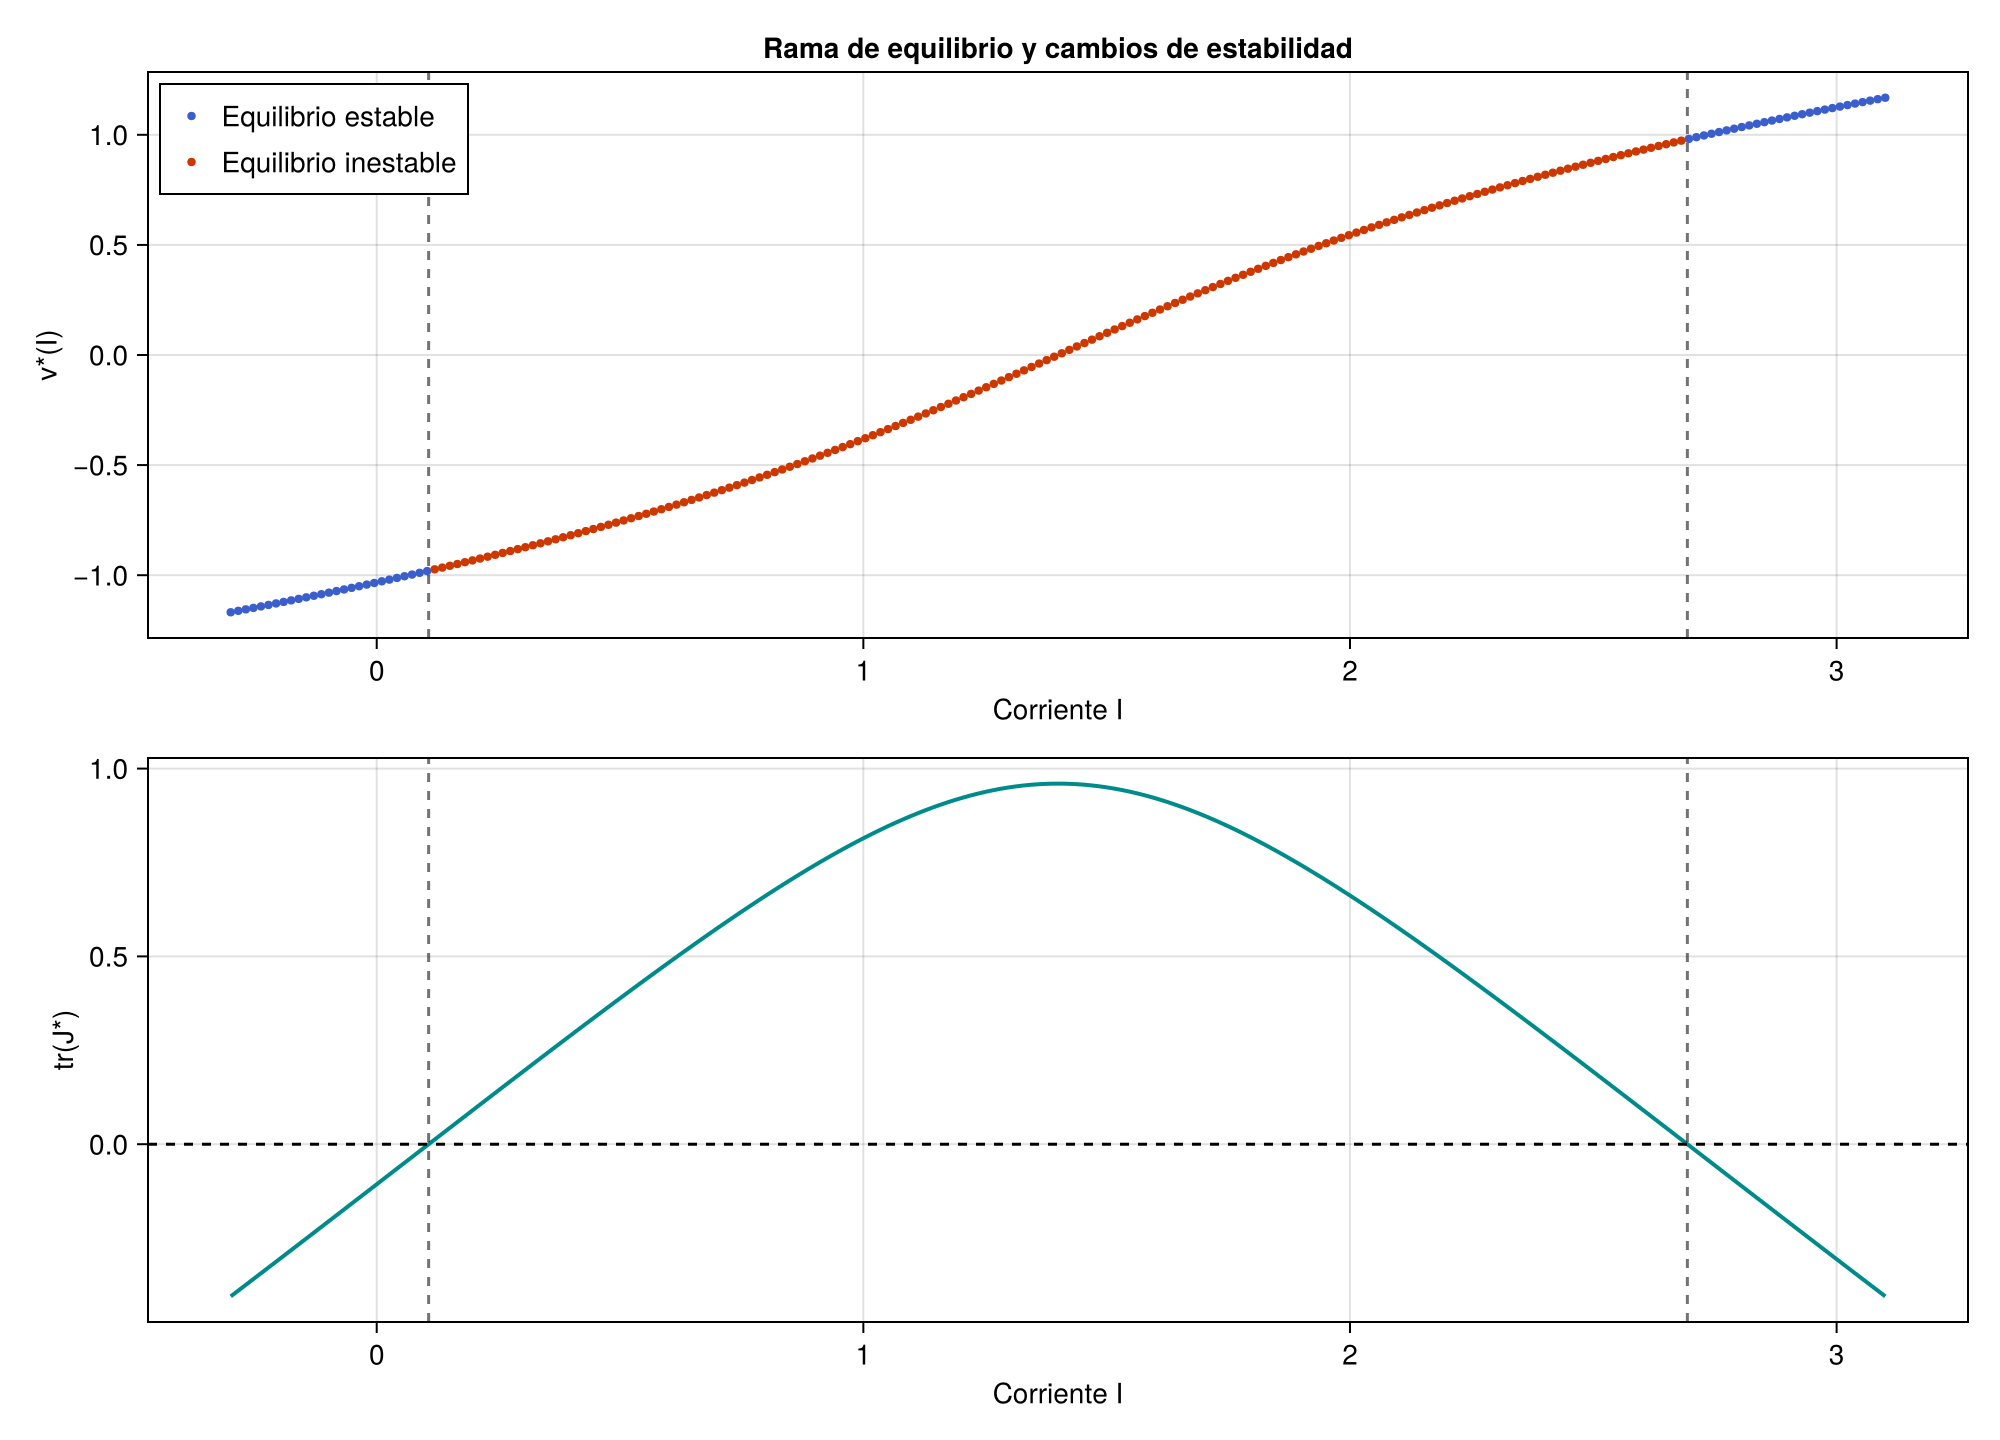

CairoMakie.Screen{IMAGE}


In [4]:
eq_sweep = equilibrium_sweep(p, range(-0.3, 3.1, length=220))
fig_hopf = plot_hopf_diagram(p, eq_sweep)
display(fig_hopf)

## 3. Detección de ciclo por cruces ascendentes

Se integra una trayectoria larga. Después de descartar el transitorio se consideran los últimos **tres períodos de retorno** a la sección $v=v^*$. Para considerar que hay un candidato a ciclo, deben estabilizarse la amplitud y el período. Esto evita identificar como ciclo a un tramo transitorio que todavía cambia con el tiempo.

In [5]:
det = detect_limit_cycle(p;
    u0=(-1.4,-0.2), transient=400.0, window=350.0, dt=0.25)
@show det.status det.crossings det.period det.amplitude_v
@show det.relative_period_spread det.relative_amplitude_spread

@assert det.status == :periodic_candidate "Amplía transient/window si aún no converge"

det.status = :periodic_candidate
det.crossings = 10
det.period = 34.56845853345536
det.amplitude_v = 3.922329271745365
det.relative_period_spread = 8.877535161571523e-5
det.relative_amplitude_spread = 0.00022158255642947648


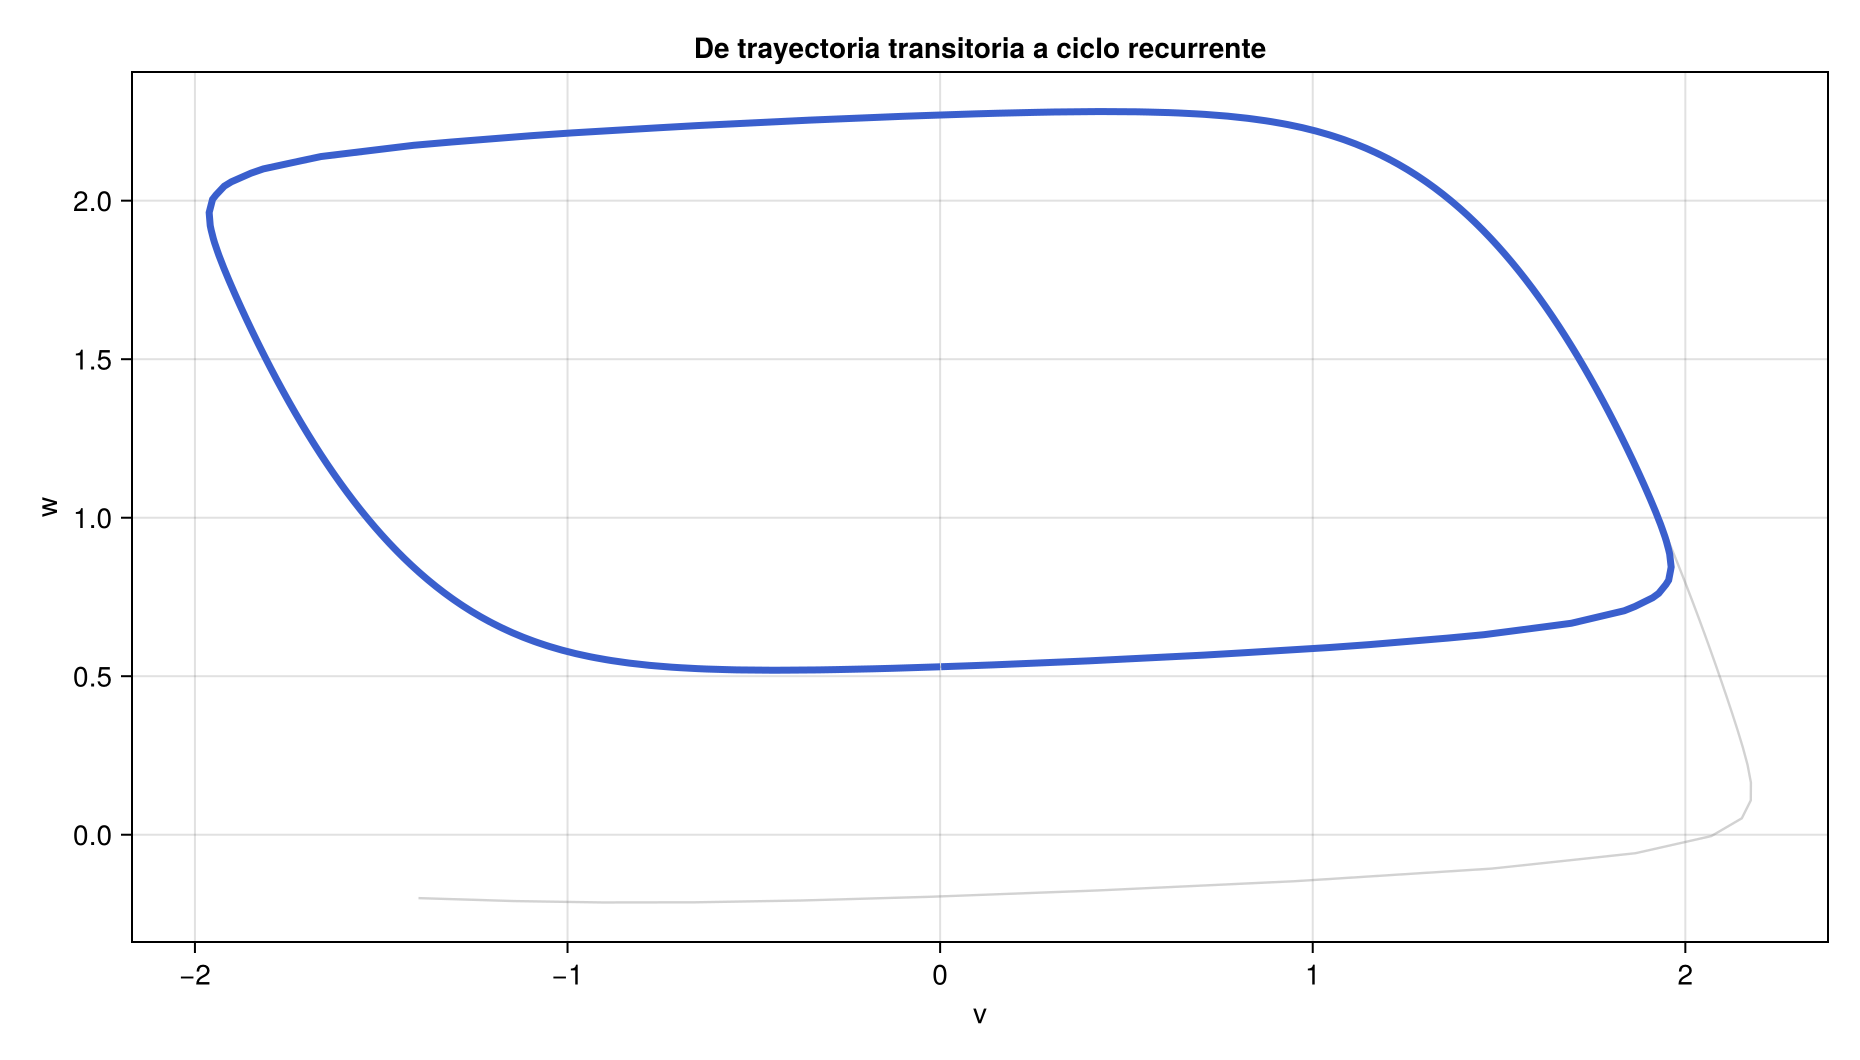

CairoMakie.Screen{IMAGE}


In [6]:
# Retrato de fase incluyendo transitorio (en gris) y último ciclo (en azul)
fig = Figure(size=(930,530))
ax = Axis(fig[1,1],title="De trayectoria transitoria a ciclo recurrente",
          xlabel="v",ylabel="w")
lines!(ax, [z[1] for z in det.solution.u],
       [z[2] for z in det.solution.u]; color=(:gray,0.35),linewidth=1.2)
recent = [det.solution(t) for t in range(det.crossing_time-det.period,
                                         det.crossing_time,length=450)]
lines!(ax, [z[1] for z in recent], [z[2] for z in recent];
       color=:royalblue3,linewidth=3.5)
display(fig)

## 4. Refinamiento de órbita periódica (shooting)

Resolvemos $\Phi_T(z_0)-z_0=0$ junto a la condición de fase $(z_0)_1=v^*$.

La matriz fundamental $M$ verifica $\dot M=DF(z(t))M$, $M(0)=I_2$. Un multiplicador de Floquet debe ser cercano a $1$; el **otro** determina la estabilidad transversal de la órbita. De esta manera se valida numéricamente el cierre del ciclo, en lugar de depender solo de la apariencia de la curva.

orb.status = :converged
orb.iterations = 3
orb.residual = 6.232456239940703e-15
orb.period = 34.569606763416296
orb.amplitude_v = 3.9237711662627426
orb.amplitude_w = 1.7624446987408093
orb.floquet = ComplexF64[0.0 + 0.0im, 1.0000000000508673 + 0.0im]
orb.phase_multiplier = 1.0000000000508673 + 0.0im
orb.transverse_multiplier = 0.0 + 0.0im
orb.stability = :stable


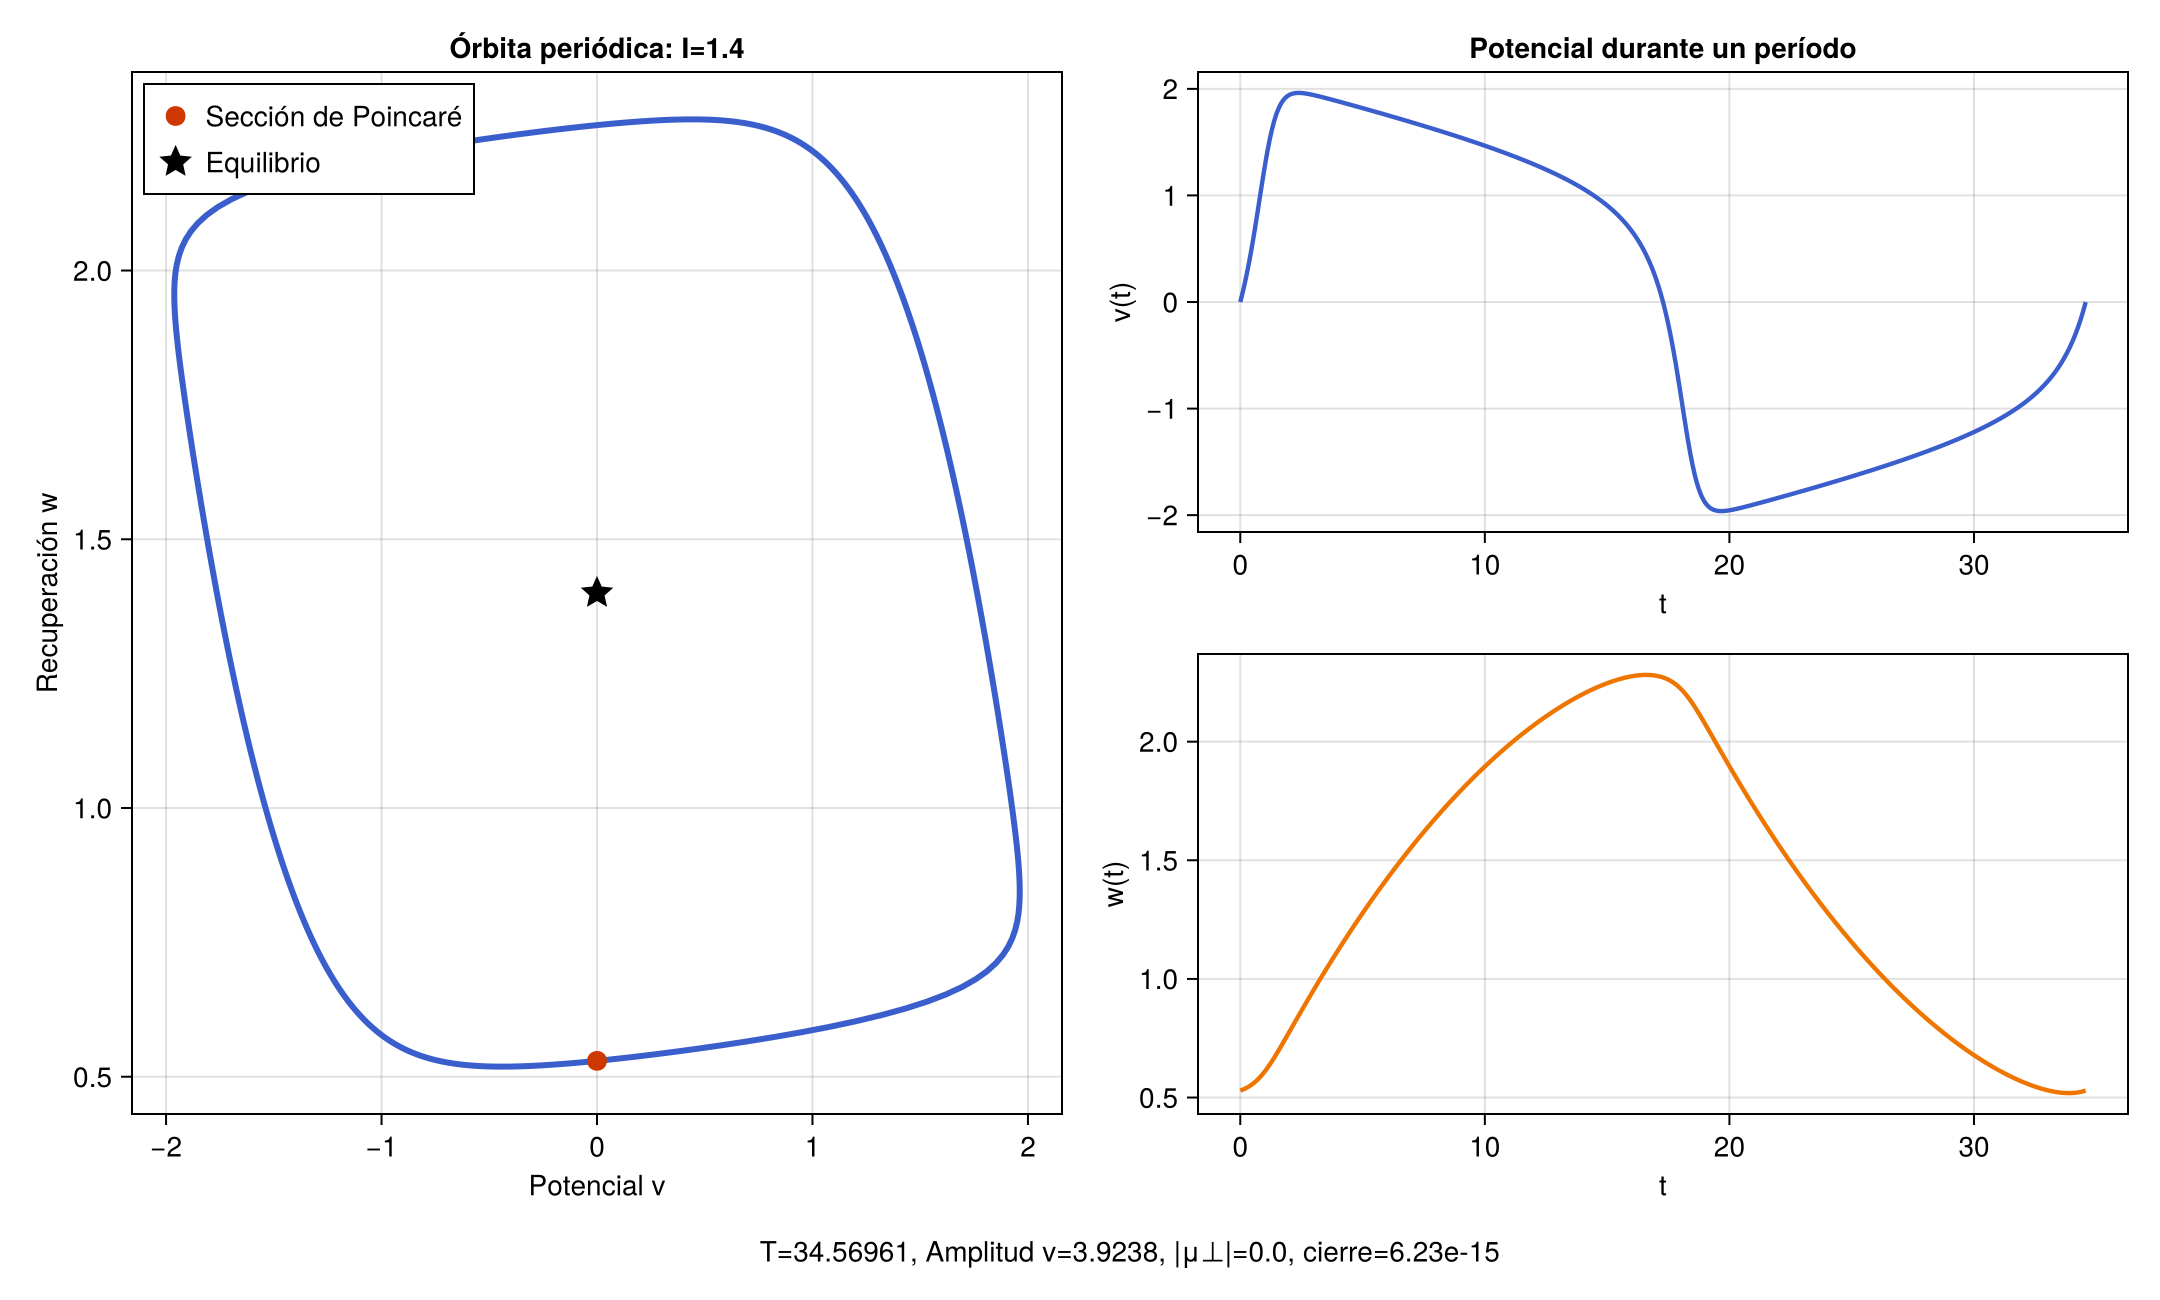

CairoMakie.Screen{IMAGE}


In [7]:
orb = refine_periodic_orbit(p, det)
@show orb.status orb.iterations orb.residual
@show orb.period orb.amplitude_v orb.amplitude_w
@show orb.floquet orb.phase_multiplier orb.transverse_multiplier orb.stability

@assert orb.status == :converged "El shooting no convergió"
display(plot_periodic_orbit(p, orb))

## 5. Barrido en la corriente externa y persistencia de oscilaciones

Si ya ejecutaste `scripts/run_stage_B.jl`, se reutiliza el barrido almacenado en JLD2. De lo contrario se calcula aquí. **Una corriente sin ciclo detectado no se grafica como amplitud cero**: puede ser un fallo de detección.

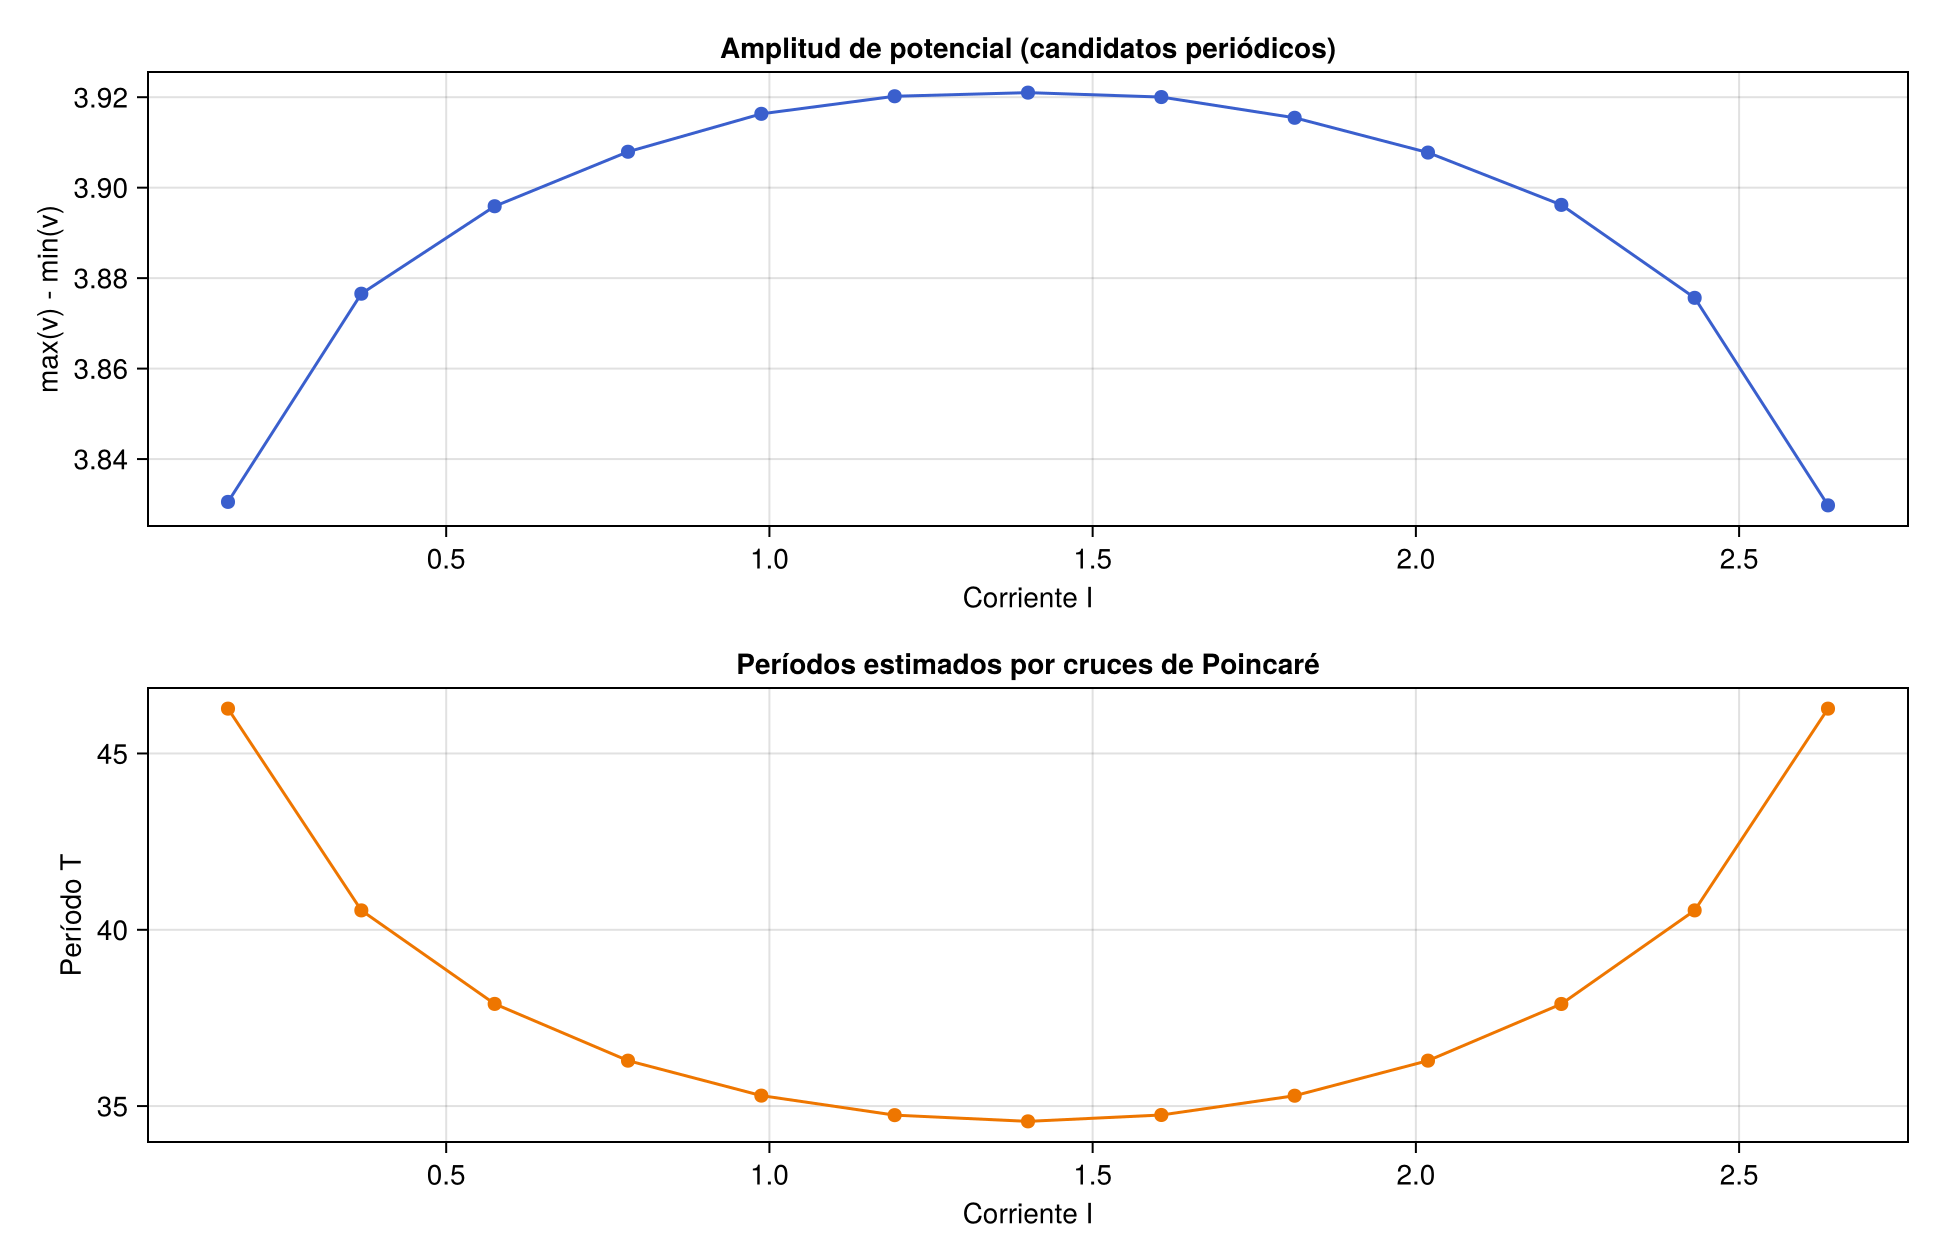

Se utilizó el barrido guardado previamente
count((d->begin
            #= k:\Repositorios\Proyecto-COPTI\notebooks\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X16sZmlsZQ==.jl:17 =#
            d.status == :periodic_candidate
        end), scan) = 13


CairoMakie.Screen{IMAGE}


In [8]:
cache = joinpath(root, "data", "processed", "etapa_B_resultados.jld2")
if isfile(cache)
    data = JLD2.load(cache)
    scan = [(current=data["scan_currents"][i],
             status=Symbol(data["scan_statuses"][i]),
             amplitude_v=data["scan_amplitudes"][i],
             period=data["scan_periods"][i])
            for i in eachindex(data["scan_currents"])]
    println("Se utilizó el barrido guardado previamente")
else
    currents = collect(range(-0.25,3.05,length=17))
    scan = [detect_limit_cycle(with_current(p,I);
                transient=400.0,window=350.0,dt=0.35)
            for I in currents]
    println("Se calculó un barrido nuevo")
end
@show count(d->d.status==:periodic_candidate,scan)
display(plot_cycle_scan(scan))

## 6. Continuación de ciclos por shooting

A partir del ciclo ya refinado hacemos pasos pequeños en la corriente. Se recalcula la sección de fase y se corrige el estado y el período por Newton. No es una continuación pseudo-arclength: puede fallar cerca de bifurcaciones secundarias, pliegues o ciclos de amplitud muy pequeña.

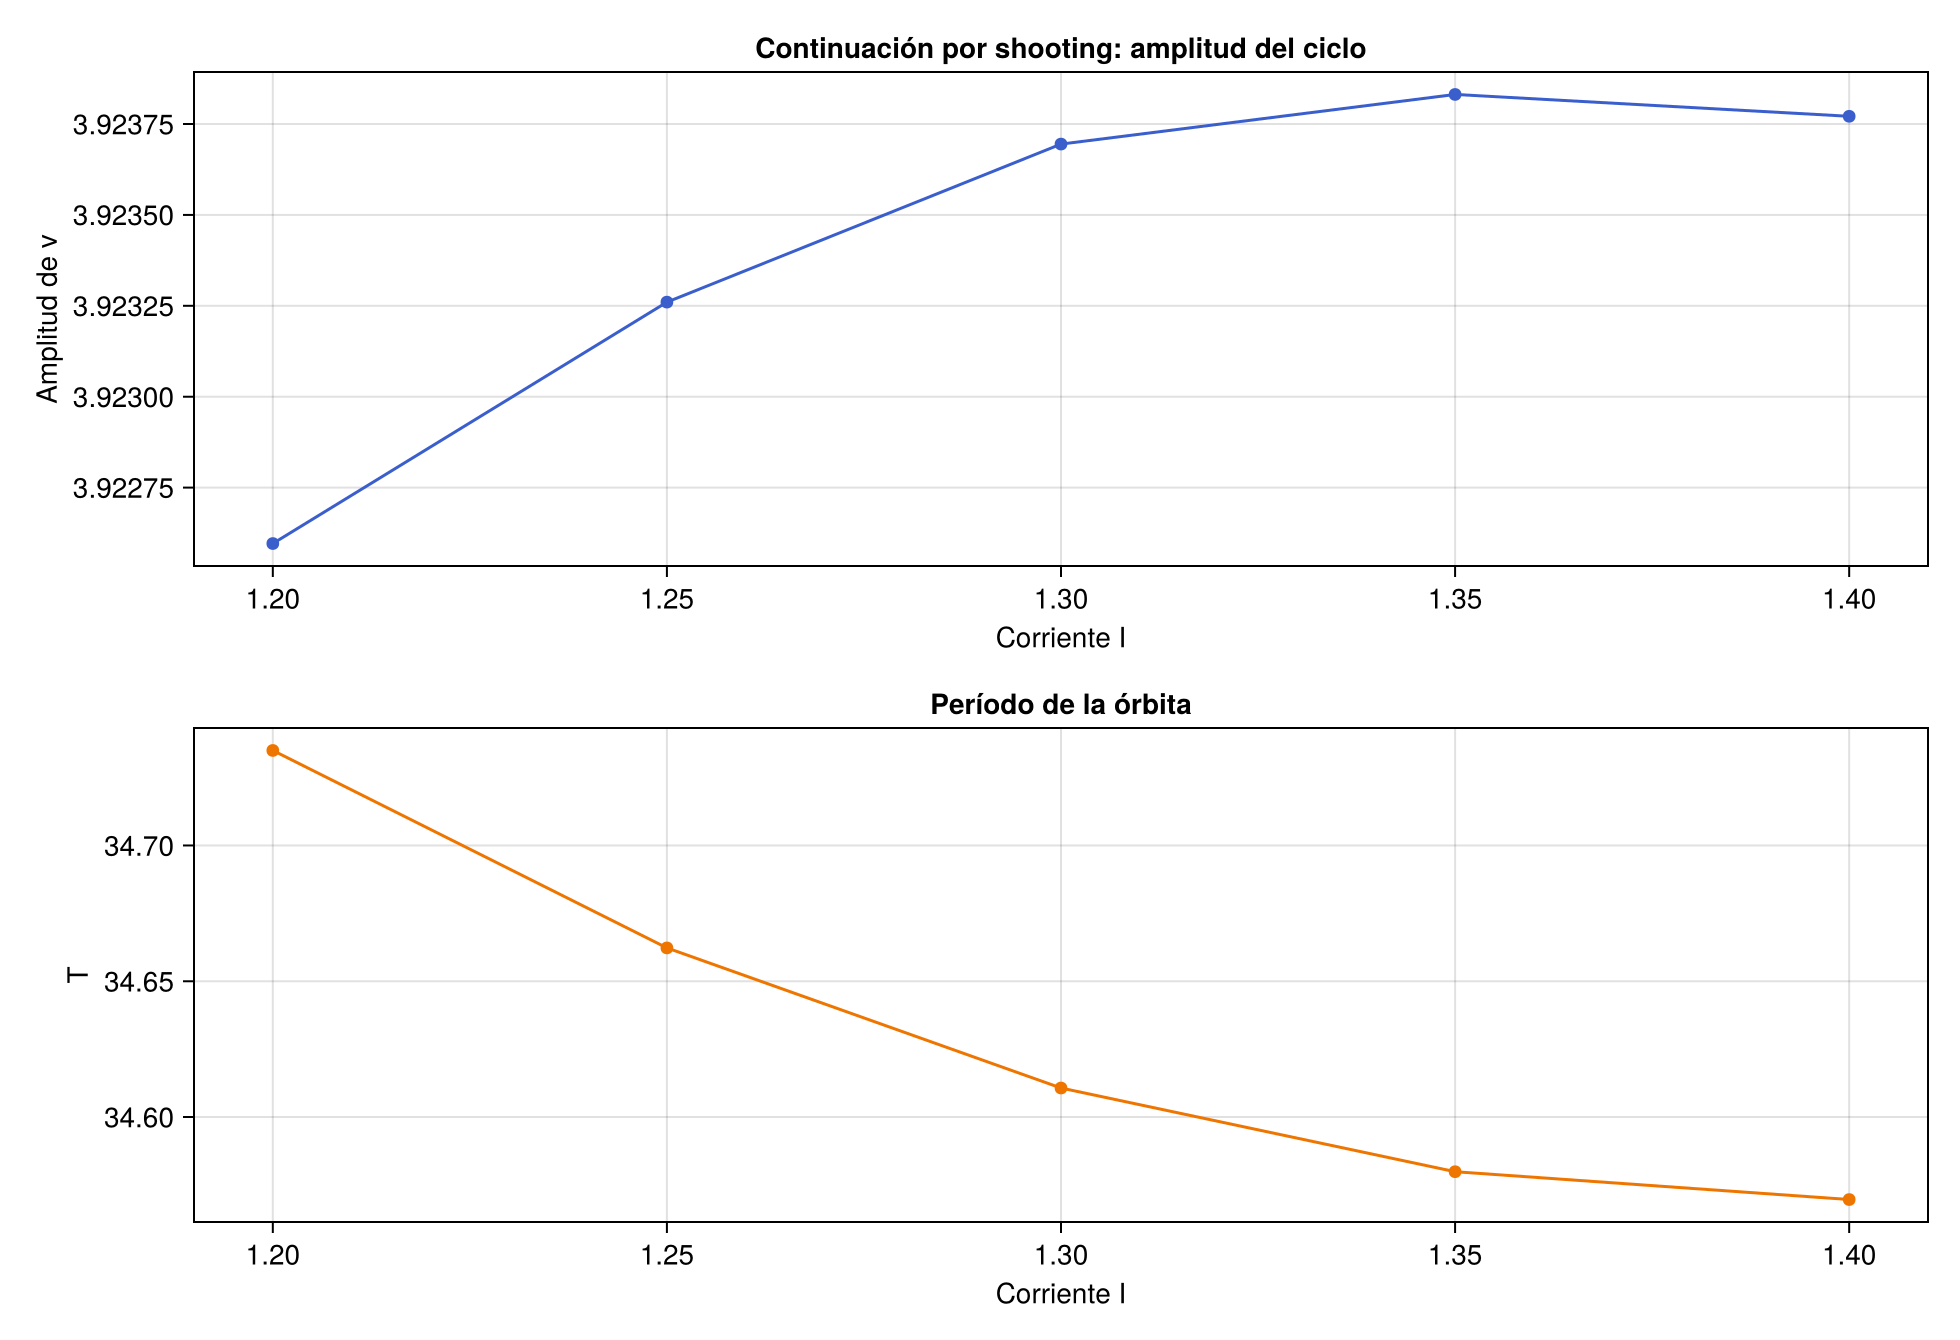

I=1.4 => converged, T=34.5696
I=1.35 => converged, T=34.5799
I=1.3 => converged, T=34.6107
I=1.25 => converged, T=34.6623
I=1.2 => converged, T=34.735


CairoMakie.Screen{IMAGE}


In [9]:
branch = continue_periodic_branch(p, orb, [1.35,1.30,1.25,1.20];maxiter=18)
branch = [(I=p.I,orbit=orb);branch]
for record in branch
    println("I=",record.I," => ",record.orbit.status,
            ", T=", round(record.orbit.period,digits=4))
end
display(plot_continuation(branch))

## 7. Estudio opcional: semillas locales para ramas inestables

La forma normal de Hopf entrega una **semilla aproximada**. Cerca de Hopf subcrítica existen ciclos locales inestables, difíciles de observar por integración temporal. Esta función no asegura que Newton converja; requiere comprobar `status` y el residuo. Para un estudio exhaustivo de ramas inestables, se recomienda más adelante BifurcationKit con continuación de pseudo-arclength.

In [10]:
seed = hopf_seed(p_sub, :minus; offset=0.001)
@show seed.params.I seed.amplitude_estimate seed.period
# Experimento opcional: descomenta para intentar corregir el ciclo inestable.
# unstable_orbit = refine_periodic_orbit(seed.params,seed.initial_state,seed.period;
#                                       tol=1e-8,maxiter=20)
# @show unstable_orbit.status unstable_orbit.residual unstable_orbit.stability

seed.params.I = 0.4118792846500434
seed.amplitude_estimate = 0.228089667218593
seed.period = 13.71103441694515


13.71103441694515

## Conclusiones y precauciones

1. Los dos valores de Hopf y el coeficiente cúbico se obtienen **analíticamente** del cuaderno; no se ajustan a ojo.
2. Un ciclo atractivo calculado por shooting tiene cierre numérico pequeño y multiplicadores coherentes con estabilidad orbital.
3. El período lineal de Hopf y el período del ciclo de gran amplitud son, en general, distintos.
4. No hemos demostrado unicidad ni estabilidad global de los ciclos; tampoco se afirma que una rama inestable se detecte por integración hacia adelante.
5. La Etapa C reutilizará este régimen oscilatorio al pasar a redes acopladas.